# SMS Spam Classification — Simple Code

**Task:** Clean text, extract Bag-of-Words / TF-IDF features, train a text classifier, report Accuracy and F1-score, and show the top 10 important words for each class.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import glob

from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

## 2. Load the dataset

In [2]:
df = pd.read_csv('spam.csv', encoding="latin-1")
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df = df[["v1", "v2"]].copy()
df.columns = ["label", "text"]
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [ ]:
df.shape

(5572, 2)

In [ ]:
df.isnull().sum()

label    0
text     0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(403)

## 3. Clean rows and encode labels

In [ ]:
df = df.dropna(subset=["label", "text"])
df = df.drop_duplicates()
df.shape

(5169, 2)

In [ ]:
df["label"] = df["label"].map({"ham": 0, "spam": 1})
df["original_text"] = df["text"]
df["label"].value_counts()

label
0    4516
1     653
Name: count, dtype: int64

## 4. Lowercase

In [ ]:
df["text"] = df["text"].apply(lambda x: x.lower())
df["text"].head()

0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: text, dtype: object

## 5. Remove punctuation

In [ ]:
def remove_punc(txt):
    return txt.translate(str.maketrans(string.punctuation, " " * len(string.punctuation)))

df["text"] = df["text"].apply(remove_punc)

## 6. Remove numbers

In [ ]:
def remove_numbers(txt):
    new = ""
    for i in txt:
        if not i.isdigit():
            new = new + i
    return new

df["text"] = df["text"].apply(remove_numbers)

## 7. Tokenize

In [ ]:
df["tokens"] = df["text"].apply(lambda x: x.split())
df["tokens"].head()

0    [go, until, jurong, point, crazy, available, o...
1                       [ok, lar, joking, wif, u, oni]
2    [free, entry, in, a, wkly, comp, to, win, fa, ...
3    [u, dun, say, so, early, hor, u, c, already, t...
4    [nah, i, don, t, think, he, goes, to, usf, he,...
Name: tokens, dtype: object

## 8. Remove stopwords

In [ ]:
stop_words = set(ENGLISH_STOP_WORDS)

def remove_stopwords(words):
    cleaned = []
    for word in words:
        if word not in stop_words:
            cleaned.append(word)
    return cleaned

df["tokens"] = df["tokens"].apply(remove_stopwords)

## 9. Stem words

In [ ]:
stemmer = PorterStemmer()

def stem_words(words):
    cleaned = []
    for word in words:
        cleaned.append(stemmer.stem(word))
    return " ".join(cleaned)

df["clean_text"] = df["tokens"].apply(stem_words)
df[["original_text", "clean_text"]].head()

,original_text,clean_text
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entri wkli comp win fa cup final tkt st text fa receiv entri question std txt rate t c s appli s
3,U dun say so early hor... U c already then say...,u dun say earli hor u c say
4,"Nah I don't think he goes to usf, he lives around here though",nah don t think goe usf live


## 10. Remove empty and repeated cleaned messages

In [ ]:
print("Empty cleaned messages:", (df["clean_text"].str.strip() == "").sum())
print("Repeated cleaned messages:", df["clean_text"].duplicated().sum())

df = df[df["clean_text"].str.strip() != ""]
df = df.drop_duplicates(subset=["clean_text"])
df.shape

Empty cleaned messages: 14
Repeated cleaned messages: 122


(5046, 5)

In [ ]:
df["label"].value_counts()

label
0    4460
1     586
Name: count, dtype: int64

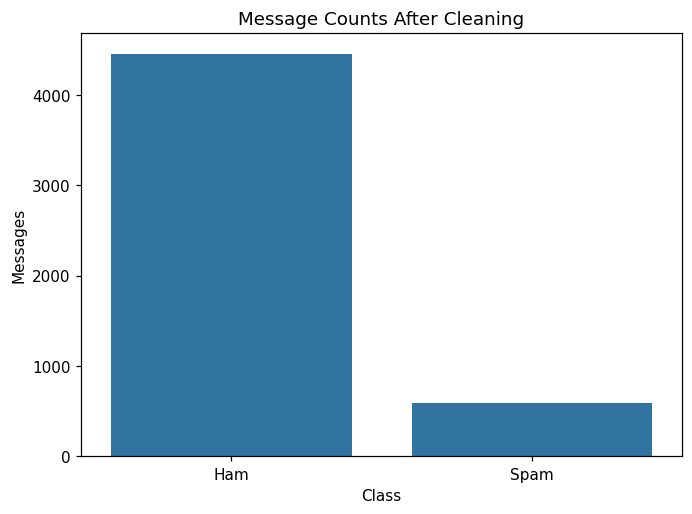

In [ ]:
sns.countplot(x=df["label"])
plt.xticks([0, 1], ["Ham", "Spam"])
plt.title("Message Counts After Cleaning")
plt.xlabel("Class")
plt.ylabel("Messages")
plt.tight_layout()
plt.show()

## 11. Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.20, random_state=42, stratify=df["label"]
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4036
Testing messages: 1010


## 12. Bag-of-Words + Naive Bayes

In [ ]:
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

nb_model = MultinomialNB()
nb_model.fit(X_train_bow, y_train)

pred_bow = nb_model.predict(X_test_bow)

In [ ]:
bow_accuracy = accuracy_score(y_test, pred_bow)
bow_f1 = f1_score(y_test, pred_bow, pos_label=1)

print("Accuracy:", bow_accuracy)
print("F1-score (spam):", bow_f1)

Accuracy: 0.9841584158415841
F1-score (spam): 0.9304347826086956


## 13. TF-IDF + Naive Bayes

In [ ]:
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

nb2_model = MultinomialNB()
nb2_model.fit(X_train_tfidf, y_train)

y_pred = nb2_model.predict(X_test_tfidf)

In [ ]:
tfidf_accuracy = accuracy_score(y_test, y_pred)
tfidf_f1 = f1_score(y_test, y_pred, pos_label=1)

print("Accuracy:", tfidf_accuracy)
print("F1-score (spam):", tfidf_f1)

Accuracy: 0.9633663366336633
F1-score (spam): 0.8121827411167513


## 14. TF-IDF + Logistic Regression

In [ ]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_tfidf, y_train)

log_pred = logistic_model.predict(X_test_tfidf)

log_accuracy = accuracy_score(y_test, log_pred)
log_f1 = f1_score(y_test, log_pred, pos_label=1)

print("Accuracy:", log_accuracy)
print("F1-score (spam):", log_f1)

Accuracy: 0.9653465346534653
F1-score (spam): 0.8258706467661692


## 15. Compare models

In [ ]:
results = pd.DataFrame({
    "Model": ["Bag-of-Words + Naive Bayes", "TF-IDF + Naive Bayes", "TF-IDF + Logistic Regression"],
    "Accuracy": [bow_accuracy, tfidf_accuracy, log_accuracy],
    "F1-score (spam)": [bow_f1, tfidf_f1, log_f1]
})
results.round(4)

,Model,Accuracy,F1-score (spam)
0,Bag-of-Words + Naive Bayes,0.9842,0.9304
1,TF-IDF + Naive Bayes,0.9634,0.8122
2,TF-IDF + Logistic Regression,0.9653,0.8259


              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       893
        Spam       0.95      0.91      0.93       117

    accuracy                           0.98      1010
   macro avg       0.97      0.95      0.96      1010
weighted avg       0.98      0.98      0.98      1010



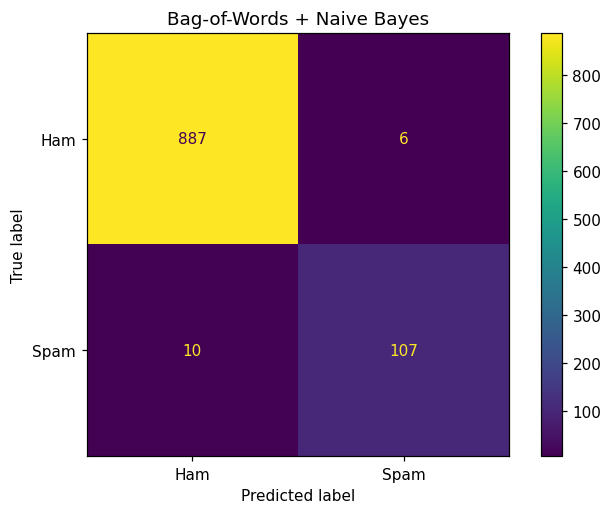

In [ ]:
print(classification_report(y_test, pred_bow, target_names=["Ham", "Spam"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_bow, display_labels=["Ham", "Spam"])
plt.title("Bag-of-Words + Naive Bayes")
plt.tight_layout()
plt.show()

## 16. Top 10 important words per class — Naive Bayes

For each word, subtract its learned ham log-probability from its spam log-probability. The score is log[P(word | spam) / P(word | ham)]: positive scores support spam, negative scores support ham. This measures how strongly a word distinguishes the classes in the trained model, rather than simply listing the most frequent words. It is learned from training data only and is not a causal explanation.

Classes are [0, 1], so row 0 is ham and row 1 is spam. We restrict this display to alphabetic tokens to show words. Stems and SMS abbreviations can appear; for example, `lt` and `gt` may reflect formatting artifacts, not meaningful content.


In [ ]:
words = bow_vectorizer.get_feature_names_out()
word_scores = nb_model.feature_log_prob_[1] - nb_model.feature_log_prob_[0]

importance = pd.DataFrame({"Word": words, "Spam score": word_scores})
importance = importance[importance["Word"].str.isalpha()]

top_spam = importance.sort_values("Spam score", ascending=False).head(10)
top_ham = importance.sort_values("Spam score").head(10)

In [ ]:
top_spam

,Word,Spam score
827,claim,5.241743
3606,prize,4.921575
4777,tone,4.843104
1942,guarante,4.352481
3874,rington,4.318579
5303,www,4.318579
1035,cs,4.283488
4897,uk,4.247120
3545,ppm,4.247120
2524,landlin,3.947016


In [ ]:
top_ham

,Word,Spam score
2703,lt,-4.533513
1939,gt,-4.525180
2667,lor,-3.961371
1079,da,-3.802307
3981,say,-3.693107
2543,later,-3.392522
868,co,-3.253409
3946,said,-3.238371
1262,do,-3.223104
2651,lol,-3.175851


In [ ]:
top_words = pd.DataFrame({
    "Top Ham Words": top_ham["Word"].values,
    "Top Spam Words": top_spam["Word"].values
})
top_words

,Top Ham Words,Top Spam Words
0,lt,claim
1,gt,prize
2,lor,tone
3,da,guarante
4,say,rington
5,later,www
6,co,cs
7,said,uk
8,do,ppm
9,lol,landlin


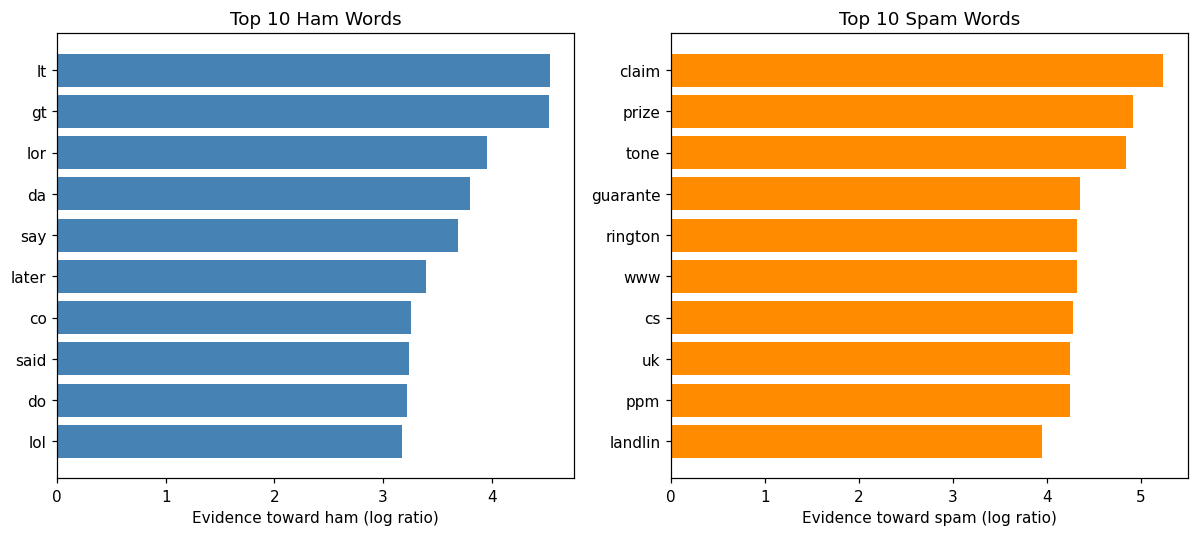

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_ham["Word"], -top_ham["Spam score"], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Top 10 Ham Words")
axes[0].set_xlabel("Evidence toward ham (log ratio)")
axes[1].barh(top_spam["Word"], top_spam["Spam score"], color="darkorange")
axes[1].invert_yaxis()
axes[1].set_title("Top 10 Spam Words")
axes[1].set_xlabel("Evidence toward spam (log ratio)")
plt.tight_layout()
plt.show()